# No retrieval and all-severities Trivy ablations against the control and the IaCGen retry loop

## Setup

In [1]:
import sys, os, re, json, csv, warnings, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
csv.field_size_limit(sys.maxsize)
sys.path.insert(0, "audit")
import repair_loop as rl

FINAL = Path("../results"); DATA = Path("../data"); RES = Path("result/final")
RUNS = os.environ.get("IACGOD_RUNS", "../runs")
CACHE = FINAL / "_analysis_cache"; CACHE.mkdir(exist_ok=True)
FIG = Path("plots/no_retrieval_trivy_all"); FIG.mkdir(parents=True, exist_ok=True)
plt.style.use("ggplot"); sns.set_palette("muted")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 80)

ARMS = ["Control", "No retrieval", "All severities"]
EXPS = {
    "CFN": {"Control": "CFN_RealAWS_DSV4F", "No retrieval": "CFN_RealAWS_NoRetrieval_DSV4Flash", "All severities": "CFN_RealAWS_TrivyAll_DSFlash"},
    "TF": {"Control": "TF_RealAWS_DSV4F", "No retrieval": "TF_RealAWS_NoRetrieval_DSV4Flash", "All severities": "TF_RealAWS_TrivyAll_DSV4Flash"},
}
PALETTE = dict(zip(ARMS, sns.color_palette("muted", 3)))
LANG_OF = {e: lang for lang, arms in EXPS.items() for e in arms.values()}
ARM_OF = {e: arm for arms in EXPS.values() for arm, e in arms.items()}

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

def holm(pvals):
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

def mcnemar_exact(a, b):
    both = int((a & b).sum()); only_a = int((a & ~b).sum()); only_b = int((~a & b).sum()); neither = int((~a & ~b).sum())
    n = only_a + only_b
    p = 1.0 if n == 0 else stats.binomtest(min(only_a, only_b), n, 0.5).pvalue
    return dict(both=both, only_ablation=only_a, only_control=only_b, neither=neither, p=p)

def paired_bootstrap(diff, reps=10000, seed=7):
    rng = np.random.default_rng(seed)
    d = np.asarray(diff, float)
    idx = rng.integers(0, len(d), (reps, len(d)))
    means = d[idx].mean(axis=1)
    return float(d.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

## Experiments and models

In [2]:
DESIGN = pd.DataFrame([
    ("CFN", "Control", EXPS["CFN"]["Control"], "validators block on CRITICAL and HIGH"),
    ("CFN", "No retrieval", EXPS["CFN"]["No retrieval"], "no Retriever, no dense or graph context"),
    ("CFN", "All severities", EXPS["CFN"]["All severities"], "Trivy blocks on every severity"),
    ("TF", "Control", EXPS["TF"]["Control"], "validators block on CRITICAL and HIGH"),
    ("TF", "No retrieval", EXPS["TF"]["No retrieval"], "no Retriever, no dense or graph context"),
    ("TF", "All severities", EXPS["TF"]["All severities"], "Trivy blocks on every severity"),
    ("CFN", "IaCGen", "CFN_RealAWS_IaCGen_DSV4Flash", "IaCGen retry loop, no agents and no retrieval"),
], columns=["language", "arm", "experiment", "change"])
DESIGN["rows"] = [json.load(open(FINAL / e / "status.json")).get("expected") for e in DESIGN.experiment]
DESIGN

,language,arm,experiment,change,rows
0,CFN,Control,CFN_RealAWS_DSV4F,validators block on CRITICAL and HIGH,250
1,CFN,No retrieval,CFN_RealAWS_NoRetrieval_DSV4Flash,"no Retriever, no dense or graph context",250
2,CFN,All severities,CFN_RealAWS_TrivyAll_DSFlash,Trivy blocks on every severity,250
3,TF,Control,TF_RealAWS_DSV4F,validators block on CRITICAL and HIGH,250
4,TF,No retrieval,TF_RealAWS_NoRetrieval_DSV4Flash,"no Retriever, no dense or graph context",250
5,TF,All severities,TF_RealAWS_TrivyAll_DSV4Flash,Trivy blocks on every severity,250
6,CFN,IaCGen,CFN_RealAWS_IaCGen_DSV4Flash,"IaCGen retry loop, no agents and no retrieval",250


## Load the merged results

In [3]:
USECOLS = {"row_number", "run_id", "status", "final_validation_passed", "iterations_used", "llm_calls_total", "token_all_tokens",
           "token_input_tokens", "token_output_tokens", "duration_seconds", "validity", "invalid_reason", "deploy_passed",
           "deploy_error_message", "val_stage_yaml_passed", "val_stage_cfn-lint_passed", "val_stage_tflint_passed",
           "val_stage_terraform-validate_passed", "val_stage_trivy_passed", "latest_error_trivy", "latest_error_cfn-lint",
           "latest_error_yaml", "latest_error_tflint", "latest_error_terraform-validate", "unfiltered_compliance_rate",
           "filtered_compliance_rate", "policy_total_policies", "policy_passed_policies"}
frames = []
for lang, arms in EXPS.items():
    ds = pd.read_csv(DATA / f"{lang.lower()}_eval_benchmark_real_aws.csv").drop_duplicates("row_number").set_index("row_number")
    dcol = "difficulty" if "difficulty" in ds else "difficulty_level"
    for arm, e in arms.items():
        r = pd.read_csv(FINAL / e / "results_final.csv", engine="python", usecols=lambda c: c in USECOLS)
        r["row_index"] = np.arange(len(r))
        r["exp"], r["arm"], r["lang"] = e, arm, lang
        r["difficulty"] = r.row_number.map(ds[dcol])
        frames.append(r)
runs = pd.concat(frames, ignore_index=True)
runs["valid"] = True
runs["passed"] = runs.final_validation_passed.astype(str).str.lower().eq("true")
runs["first_try"] = runs.passed & (runs.iterations_used == 1)
runs["arm"] = pd.Categorical(runs.arm, ARMS, ordered=True)
runs.groupby(["lang", "arm"], observed=True).agg(rows=("row_number", "size"), passed=("passed", "sum"))

rows  passed
lang arm                         
CFN  Control          250     247
     No retrieval     250     234
     All severities   250     236
TF   Control          250     246
     No retrieval     250     241
     All severities   250     239

## Pass rate

In [4]:
rows = []
for (lang, arm), g in runs.groupby(["lang", "arm"], observed=True, sort=False):
    lo, hi = wilson(int(g.passed.sum()), len(g))
    rows.append(dict(lang=lang, arm=arm, rows=len(g), passed=int(g.passed.sum()), failed=int((~g.passed).sum()), pass_rate=g.passed.mean(), ci_lo=lo, ci_hi=hi))
HEAD = pd.DataFrame(rows)
HEAD.round(4)

,lang,arm,rows,passed,failed,pass_rate,ci_lo,ci_hi
0,CFN,Control,250,247,3,0.988,0.9653,0.9959
1,CFN,No retrieval,250,234,16,0.936,0.8986,0.9602
2,CFN,All severities,250,236,14,0.944,0.9082,0.9664
3,TF,Control,250,246,4,0.984,0.9596,0.9938
4,TF,No retrieval,250,241,9,0.964,0.9330,0.9809
5,TF,All severities,250,239,11,0.956,0.9229,0.9753


## Pass rate by difficulty level

difficulty               1      2      3      4     5
lang arm                                             
CFN  Control          96.0  100.0  100.0  100.0  98.0
     No retrieval     90.0   94.0   98.0   90.0  96.0
     All severities   98.0   90.0   96.0   96.0  92.0
TF   Control         100.0  100.0  100.0   98.0  94.0
     No retrieval     98.0  100.0   96.0   94.0  94.0
     All severities   98.0   98.0  100.0   94.0  88.0

difficulty           1  2  3  4  5
lang arm                          
CFN  Control         2  0  0  0  1
     No retrieval    5  3  1  5  2
     All severities  1  5  2  2  4
TF   Control         0  0  0  1  3
     No retrieval    1  0  2  3  3
     All severities  1  1  0  3  6

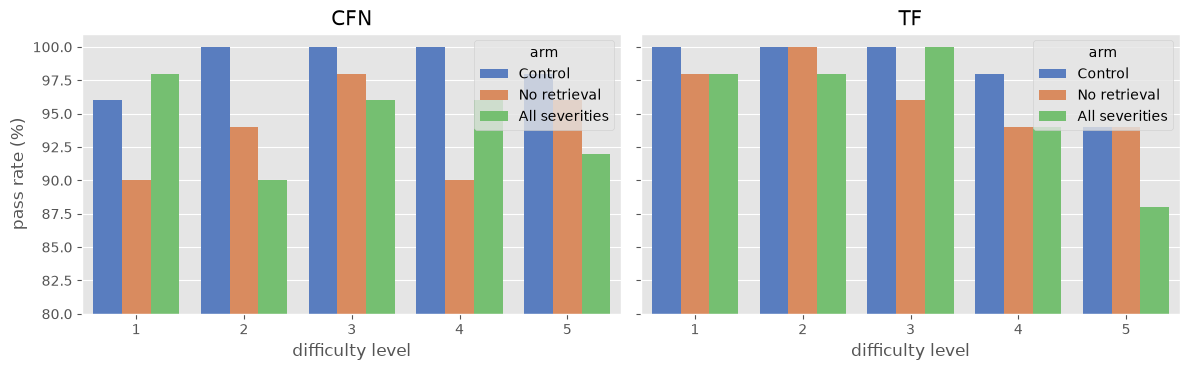

In [5]:
valid_runs = runs[runs.valid]
by_level = valid_runs.pivot_table(index=["lang", "arm"], columns="difficulty", values="passed", aggfunc="mean", observed=True).mul(100).round(1)
fails_level = valid_runs[~valid_runs.passed].pivot_table(index=["lang", "arm"], columns="difficulty", values="row_number", aggfunc="count", observed=True).fillna(0).astype(int)
display(by_level)
display(fails_level)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, lang in zip(axes, EXPS):
    d = valid_runs[valid_runs.lang == lang].groupby(["difficulty", "arm"], observed=True).passed.mean().mul(100).reset_index()
    sns.barplot(data=d, x="difficulty", y="passed", hue="arm", hue_order=ARMS, palette=PALETTE, ax=ax)
    ax.set_title(lang); ax.set_xlabel("difficulty level"); ax.set_ylabel("pass rate (%)"); ax.set_ylim(80, 101)
plt.tight_layout(); plt.savefig(FIG / "pass_by_level.png", dpi=160); plt.show()

## First-attempt pass and repair effort

In [6]:
def effort(g):
    v = g[g.valid]
    return pd.Series(dict(
        first_try_rate=v.first_try.mean(), mean_iterations=v.iterations_used.mean(), median_iterations=v.iterations_used.median(),
        p90_iterations=v.iterations_used.quantile(0.9), hit_cap_15=int((v.iterations_used >= 15).sum()),
        mean_llm_calls=v.llm_calls_total.mean(), mean_tokens_k=v.token_all_tokens.mean() / 1e3, median_tokens_k=v.token_all_tokens.median() / 1e3, max_tokens_m=v.token_all_tokens.max() / 1e6, total_tokens_m=v.token_all_tokens.sum() / 1e6,
        median_minutes=v.duration_seconds.median() / 60, total_hours=v.duration_seconds.sum() / 3600))
EFFORT = runs.groupby(["lang", "arm"], observed=True).apply(effort).round(3)
EFFORT

first_try_rate  mean_iterations  median_iterations  p90_iterations  hit_cap_15  mean_llm_calls  mean_tokens_k  median_tokens_k  max_tokens_m  total_tokens_m  median_minutes  total_hours
lang arm                                                                                                                                                                                                      
CFN  Control                  0.192            3.844                3.0             8.0         3.0          10.148        151.111           39.514         2.239          37.778           9.182       88.248
     No retrieval             0.224            4.116                3.0            10.0        19.0           8.232        361.875           56.540        17.683          90.469           8.322      101.673
     All severities           0.136            4.368                3.0             8.0        16.0          11.032        193.316           50.946         2.392          48.329           4.910       49.719
TF   Control                  0.400            3.100                2.0             7.0         4.0           7.976        141.284           27.360         2.358          35.321           8.836       69.728
     No retrieval             0.240            4.392                3.0            10.0        12.0           8.784        135.859           37.278         1.404          33.965           7.139       52.662
     All severities           0.148            4.624                4.0             9.0        11.0          11.456        233.743           93.016         3.014          58.436          12.283       93.737

## Paired comparison with the control on all rows

In [7]:
def common(lang, arm):
    c = runs[(runs.lang == lang) & (runs.arm == "Control") & runs.valid].set_index("row_number")
    a = runs[(runs.lang == lang) & (runs.arm == arm) & runs.valid].set_index("row_number")
    idx = c.index.intersection(a.index)
    return c.loc[idx], a.loc[idx]

pair_rows, metric_rows = [], []
for lang in EXPS:
    for arm in ARMS[1:]:
        c, a = common(lang, arm)
        m = mcnemar_exact(a.passed.values, c.passed.values)
        pair_rows.append(dict(lang=lang, arm=arm, rows=len(c), control_pass=int(c.passed.sum()), ablation_pass=int(a.passed.sum()), **m))
        for metric, scale in (("iterations_used", 1), ("llm_calls_total", 1), ("token_all_tokens", 1e3), ("duration_seconds", 60)):
            d = ((a[metric] - c[metric]).astype(float) / scale).dropna()
            mean, lo, hi = paired_bootstrap(d.values)
            nz = d[d != 0]
            w = stats.wilcoxon(nz).pvalue if len(nz) > 0 else 1.0
            metric_rows.append(dict(lang=lang, arm=arm, metric={"iterations_used": "iterations", "llm_calls_total": "LLM calls", "token_all_tokens": "tokens (k)", "duration_seconds": "minutes"}[metric],
                                    mean_diff=mean, ci_lo=lo, ci_hi=hi, wilcoxon_p=w))
PAIRS = pd.DataFrame(pair_rows)
PAIRS["p_holm"] = np.nan
for lang in EXPS:
    m = PAIRS.lang == lang
    PAIRS.loc[m, "p_holm"] = holm(PAIRS.loc[m, "p"].values)
METRICS = pd.DataFrame(metric_rows)
METRICS["p_holm"] = np.nan
for lang in EXPS:
    for met in METRICS.metric.unique():
        m = (METRICS.lang == lang) & (METRICS.metric == met)
        METRICS.loc[m, "p_holm"] = holm(METRICS.loc[m, "wilcoxon_p"].values)
display(PAIRS.round(4))
display(METRICS.round(4))

,lang,arm,rows,control_pass,ablation_pass,both,only_ablation,only_control,neither,p,p_holm
0,CFN,No retrieval,250,247,234,233,1,14,2,0.0010,0.0020
1,CFN,All severities,250,247,236,234,2,13,1,0.0074,0.0074
2,TF,No retrieval,250,246,241,238,3,8,1,0.2266,0.2266
3,TF,All severities,250,246,239,236,3,10,1,0.0923,0.1846


,lang,arm,metric,mean_diff,ci_lo,ci_hi,wilcoxon_p,p_holm
0,CFN,No retrieval,iterations,0.2720,-0.1280,0.6760,0.4258,0.4258
1,CFN,No retrieval,LLM calls,-1.9160,-2.9240,-0.9480,0.0000,0.0000
2,CFN,No retrieval,tokens (k),210.7643,54.9904,421.3183,0.0273,0.0546
3,CFN,No retrieval,minutes,3.2220,-2.1434,8.7478,0.9044,0.9044
4,CFN,All severities,iterations,0.5240,0.0600,0.9921,0.0311,0.0622
5,CFN,All severities,LLM calls,0.8840,-0.4201,2.2160,0.1577,0.1577
6,CFN,All severities,tokens (k),42.2052,-0.2068,86.6711,0.0781,0.0781
7,CFN,All severities,minutes,-9.2468,-13.9470,-4.7806,0.0000,0.0000
8,TF,No retrieval,iterations,1.2920,0.8800,1.7120,0.0000,0.0000
9,TF,No retrieval,LLM calls,0.8080,-0.2081,1.8040,0.0053,0.0053


## Direct comparison of the two ablations

In [8]:
direct = []
for lang in EXPS:
    a = runs[(runs.lang == lang) & (runs.arm == "No retrieval") & runs.valid].set_index("row_number")
    b = runs[(runs.lang == lang) & (runs.arm == "All severities") & runs.valid].set_index("row_number")
    idx = a.index.intersection(b.index)
    m = mcnemar_exact(a.loc[idx].passed.values, b.loc[idx].passed.values)
    direct.append(dict(lang=lang, rows=len(idx), no_retrieval_pass=int(a.loc[idx].passed.sum()), all_severities_pass=int(b.loc[idx].passed.sum()), **m))
pd.DataFrame(direct).round(4)

,lang,rows,no_retrieval_pass,all_severities_pass,both,only_ablation,only_control,neither,p
0,CFN,250,234,236,222,12,14,2,0.8450
1,TF,250,241,239,233,8,6,3,0.7905


## Rows that did not pass

In [9]:
STAGES = {"CFN": [("yaml", "val_stage_yaml_passed"), ("cfn-lint", "val_stage_cfn-lint_passed"), ("trivy", "val_stage_trivy_passed")],
          "TF": [("tflint", "val_stage_tflint_passed"), ("terraform-validate", "val_stage_terraform-validate_passed"), ("trivy", "val_stage_trivy_passed")]}

def fail_stage(r):
    if pd.isna(r.get("iterations_used")):
        return "no run"
    for name, col in STAGES[r.lang]:
        v = r.get(col)
        if pd.notna(v) and not bool(v):
            return name
    if pd.notna(r.get("deploy_passed")) and not bool(r.deploy_passed):
        return "deploy"
    return "unknown"

def fail_text(r):
    stage = r.fail_stage
    if stage == "deploy":
        return str(r.get("deploy_error_message") or "")[:140].replace("\n", " ")
    col = f"latest_error_{stage}"
    return str(r.get(col) or "")[:140].replace("\n", " ")

bad = runs[~runs.passed].copy()
bad["fail_stage"] = bad.apply(fail_stage, axis=1)
bad["detail"] = bad.apply(fail_text, axis=1)
FAIL_TABLE = bad[["lang", "arm", "row_number", "difficulty", "fail_stage", "iterations_used", "detail"]].sort_values(["lang", "arm", "row_number"])
display(FAIL_TABLE.groupby(["lang", "arm", "fail_stage"], observed=True).size().unstack(fill_value=0))
FAIL_TABLE

fail_stage           cfn-lint  deploy  terraform-validate  trivy
lang arm                                                        
CFN  Control                0       2                   0      1
     No retrieval           2      14                   0      0
     All severities         3       8                   0      3
TF   Control                0       2                   1      1
     No retrieval           0       4                   4      1
     All severities         0       9                   0      2

,lang,arm,row_number,difficulty,fail_stage,iterations_used,detail
2,CFN,Control,2,1,deploy,15.0,"Framework: Resource handler returned message: ""AWS::Backup::Framework with A..."
6,CFN,Control,6,1,deploy,15.0,"CloudWanCoreNetwork: Resource handler returned message: ""null"" (RequestToken..."
154,CFN,Control,163,5,trivy,15.0,[AWS-0015] HIGH: CloudTrail should use Customer managed keys to encrypt the ...
252,CFN,No retrieval,2,1,deploy,15.0,"BackupAuditFramework: Resource handler returned message: ""AWS::Backup::Frame..."
256,CFN,No retrieval,6,1,cfn-lint,15.0,nan
270,CFN,No retrieval,20,1,deploy,15.0,"AccessAnalyzer: Resource handler returned message: ""Analyzer with the same n..."
276,CFN,No retrieval,26,1,deploy,15.0,"StateMachine: Resource handler returned message: ""The state machine IAM Role..."
283,CFN,No retrieval,34,1,deploy,15.0,"SelfSignedCertificate: Resource handler returned message: ""The first domain ..."
286,CFN,No retrieval,37,2,deploy,15.0,CreateEventBus: Received response status [FAILED] from custom resource. Mess...
295,CFN,No retrieval,46,2,deploy,15.0,stack: An error occurred (ValidationError) when calling the CreateStack oper...


## Rows that fail in more than one arm

In [10]:
rep = FAIL_TABLE.groupby(["lang", "row_number"]).agg(arms=("arm", lambda s: ", ".join(map(str, s))), n=("arm", "size"), difficulty=("difficulty", "first"), stage=("fail_stage", lambda s: ", ".join(sorted(set(s))))).query("n > 1")
rep.sort_values("n", ascending=False)

arms  n  difficulty                              stage
lang row_number                                                                                         
TF   184         Control, No retrieval, All severities  3           5  deploy, terraform-validate, trivy
CFN  2                           Control, No retrieval  2           1                             deploy
     6                           Control, No retrieval  2           1                   cfn-lint, deploy
     46                   No retrieval, All severities  2           2                             deploy
     163                       Control, All severities  2           5                    cfn-lint, trivy
     174                  No retrieval, All severities  2           5                             deploy
TF   168                  No retrieval, All severities  2           5         deploy, terraform-validate
     311                  No retrieval, All severities  2           4                             deploy

## Iteration-level repair loop

In [11]:
INDEX = None
def load_iters(e):
    global INDEX
    src = FINAL / e / "results_final.csv"; p = CACHE / f"iters_{e}.pkl"; p_ids = CACHE / f"iters_{e}.run_ids.json"
    rids = sorted(runs.loc[runs.exp == e, "run_id"].dropna().astype(str).unique())
    if p.exists() and p_ids.exists() and json.load(open(p_ids)) == rids:
        return pd.read_pickle(p)
    if not Path(RUNS).exists():
        raise FileNotFoundError(f"{RUNS} is missing and no cache for {e}; set IACGOD_RUNS")
    if INDEX is None:
        INDEX = rl.index_runs(RUNS)
    meta = runs.loc[runs.exp == e, ["run_id", "row_number"]].dropna()
    blocking = "all" if e in (EXPS["CFN"]["All severities"], EXPS["TF"]["All severities"]) else rl.BLOCKING_DEFAULT
    df = rl.build_iteration_table(meta, RUNS, LANG_OF[e], index=INDEX, blocking=blocking)
    df.to_pickle(p); json.dump(rids, open(p_ids, "w"))
    return df

parts = []
for e in [x for arms in EXPS.values() for x in arms.values()]:
    d = load_iters(e); d["exp"] = e; d["arm"] = ARM_OF[e]; d["lang"] = LANG_OF[e]
    parts.append(d)
iters = pd.concat(parts, ignore_index=True)
CLASSES = ["syntax", "schema", "security", "deploy"]
for c in CLASSES:
    iters[f"{c}_ran"] = iters[f"{c}_ran"].fillna(False).astype(bool)
    iters[f"{c}_ok"] = iters[f"{c}_ok"].fillna(True).astype(bool)
    iters[f"{c}_keys"] = iters[f"{c}_keys"].fillna("")
iters["arm"] = pd.Categorical(iters.arm, ARMS, ordered=True)
iters.groupby(["lang", "arm"], observed=True).agg(rows=("run_id", "nunique"), iterations=("iteration", "size"))

rows  iterations
lang arm                             
CFN  Control          250         961
     No retrieval     250        1029
     All severities   250        1092
TF   Control          250         775
     No retrieval     250        1098
     All severities   250        1156

In [12]:
tax = []
for (lang, arm), g in iters.groupby(["lang", "arm"], observed=True, sort=False):
    n_rows = g.run_id.nunique(); first = g[g.iteration == 1]
    rec = dict(lang=lang, arm=arm, rows=n_rows, iterations=len(g))
    for c in CLASSES:
        failing = g[g[f"{c}_ran"] & ~g[f"{c}_ok"]]
        rec[f"{c}_fail_iters"] = len(failing)
        rec[f"{c}_rows_affected"] = failing.run_id.nunique()
        rec[f"{c}_first_iter_fail_pct"] = 100 * (first[f"{c}_ran"] & ~first[f"{c}_ok"]).mean()
    tax.append(rec)
TAX = pd.DataFrame(tax).round(2)
TAX

,lang,arm,rows,iterations,syntax_fail_iters,syntax_rows_affected,syntax_first_iter_fail_pct,schema_fail_iters,schema_rows_affected,schema_first_iter_fail_pct,security_fail_iters,security_rows_affected,security_first_iter_fail_pct,deploy_fail_iters,deploy_rows_affected,deploy_first_iter_fail_pct
0,CFN,Control,250,961,65,47,17.6,225,149,54.8,97,71,10.4,379,115,13.6
1,CFN,No retrieval,250,1029,37,31,10.0,245,155,54.4,88,62,8.0,457,122,14.4
2,CFN,All severities,250,1092,21,19,6.8,223,141,44.0,271,160,35.6,361,111,6.8
3,TF,Control,250,775,204,99,35.6,0,0,0.0,82,64,13.2,243,84,11.2
4,TF,No retrieval,250,1098,536,162,62.8,0,0,0.0,73,52,6.0,248,82,7.2
5,TF,All severities,250,1156,143,100,30.0,0,0,0.0,356,175,48.8,418,143,6.4


,lang,arm,syntax,schema,security,deploy,per_row
0,CFN,Control,8.49,29.37,12.66,49.48,3.06
1,CFN,No retrieval,4.47,29.63,10.64,55.26,3.31
2,CFN,All severities,2.40,25.46,30.94,41.21,3.50
3,TF,Control,38.56,0.00,15.50,45.94,2.12
4,TF,No retrieval,62.54,0.00,8.52,28.94,3.43
5,TF,All severities,15.59,0.00,38.82,45.58,3.67


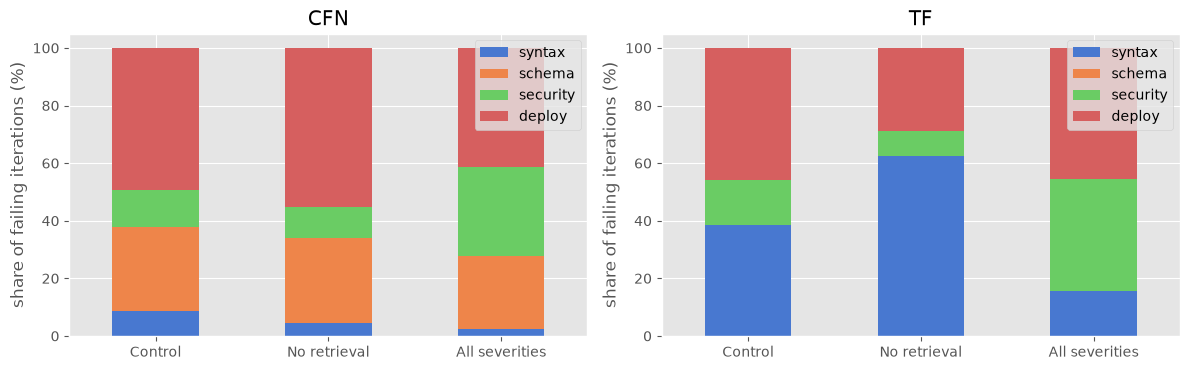

In [13]:
share = []
for (lang, arm), g in iters.groupby(["lang", "arm"], observed=True, sort=False):
    fails = {c: int((g[f"{c}_ran"] & ~g[f"{c}_ok"]).sum()) for c in CLASSES}
    tot = sum(fails.values()) or 1
    share.append(dict(lang=lang, arm=arm, **{c: 100 * v / tot for c, v in fails.items()}, per_row=sum(fails.values()) / g.run_id.nunique()))
SHARE = pd.DataFrame(share).round(2)
display(SHARE)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, lang in zip(axes, EXPS):
    d = SHARE[SHARE.lang == lang].set_index("arm")[CLASSES]
    d.plot(kind="bar", stacked=True, ax=ax, color=sns.color_palette("muted", 4), rot=0)
    ax.set_title(lang); ax.set_ylabel("share of failing iterations (%)"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "failing_iteration_classes.png", dpi=160); plt.show()

## Security iterations

In [14]:
sec = []
for lang in EXPS:
    c = iters[(iters.lang == lang) & (iters.arm == "Control")]
    for arm in ARMS:
        g = iters[(iters.lang == lang) & (iters.arm == arm)]
        per = g.assign(sf=(g.security_ran & ~g.security_ok)).groupby("run_id").sf.sum()
        sec.append(dict(lang=lang, arm=arm, rows=len(per), rows_with_security_fail=int((per > 0).sum()), security_fail_iters=int(per.sum()),
                        mean_per_row=per.mean(), max_per_row=int(per.max())))
pd.DataFrame(sec).round(3)

,lang,arm,rows,rows_with_security_fail,security_fail_iters,mean_per_row,max_per_row
0,CFN,Control,250,71,97,0.388,11
1,CFN,No retrieval,250,62,88,0.352,5
2,CFN,All severities,250,160,271,1.084,11
3,TF,Control,250,64,82,0.328,13
4,TF,No retrieval,250,52,73,0.292,9
5,TF,All severities,250,175,356,1.424,11


## Retrieval-dependent errors

In [15]:
def key_counts(g, cls):
    s = g[f"{cls}_keys"]
    s = s[s != ""].str.split(";").explode().str.strip()
    return s[s != ""].value_counts()

for lang in EXPS:
    for cls in ("schema", "deploy"):
        tab = pd.concat({arm: key_counts(iters[(iters.lang == lang) & (iters.arm == arm)], cls) for arm in ARMS}, axis=1).fillna(0).astype(int)
        tab["total"] = tab.sum(axis=1)
        print(f"{lang} {cls} error keys (iteration failures)")
        display(tab.sort_values("total", ascending=False).head(12))

CFN schema error keys (iteration failures)


,Control,No retrieval,All severities,total
schema_keys,,,,
E3002,37,40,68,145
E0000,31,28,20,79
E3004,13,15,25,53
E3006,7,13,7,27
E3021,2,0,20,22
E3003,8,9,5,22
E3003|E3002,8,10,2,20
E2533,4,11,2,17
E6101,3,6,8,17


CFN deploy error keys (iteration failures)


,Control,No retrieval,All severities,total
deploy_keys,,,,
parameter,28,38,19,85
AWS::StepFunctions::StateMachine,21,31,2,54
unknown-resource,23,16,7,46
stack-level,6,5,28,39
AWS::NetworkManager::CoreNetwork,14,9,9,32
AWS::IAM::Role,16,10,2,28
AWS::Backup::Framework,12,12,3,27
AWS::ECS::Service,6,8,6,20
AWS::Route53::RecordSet,5,8,6,19


TF schema error keys (iteration failures)


,Control,No retrieval,All severities,total
schema_keys,,,,


TF deploy error keys (iteration failures)


,Control,No retrieval,All severities,total
deploy_keys,,,,
aws_cloudwatch_log_group,2,4,56,62
aws_s3_bucket,6,17,15,38
aws_iam_role,4,10,22,36
apply: No value for required variable,14,6,11,31
aws_iam_role_policy_attachment,5,6,14,25
aws_vpc,21,4,0,25
aws_s3_bucket_acl,2,3,16,21
aws_kms_alias,6,4,8,18
aws_kms_key,6,2,6,14


## Against the IaCGen retry loop

In [16]:
IACGEN = "CFN_RealAWS_IaCGen_DSV4Flash"
ig = pd.read_csv(FINAL / IACGEN / "results_final.csv", engine="python", usecols=lambda c: c in {"row_number", "run_id", "final_validation_passed"})
ig["deploys"] = ig.final_validation_passed.astype(str).str.lower().eq("true")
it = pd.read_csv(RES / f"Trivy_{IACGEN}.csv", engine="python").drop_duplicates("run_id")
it["severe"] = (it.severity_critical_failed.fillna(0) + it.severity_high_failed.fillna(0)) > 0
ig = ig.merge(it[["run_id", "severe"]], on="run_id", how="left")
ig["deploys_and_secure"] = ig.deploys & ig.severe.eq(False)
ig = ig.set_index("row_number")
vs = []
for crit in ("deploys", "deploys_and_secure"):
    for arm in ARMS:
        m = runs[(runs.lang == "CFN") & (runs.arm == arm)].set_index("row_number")
        idx = m.index.intersection(ig.index)
        t = mcnemar_exact(m.loc[idx].passed.values, ig.loc[idx, crit].values)
        vs.append(dict(iacgen_criterion=crit, arm=arm, rows=len(idx), arm_pass=int(m.loc[idx].passed.sum()), iacgen_pass=int(ig.loc[idx, crit].sum()),
                       only_arm=t["only_ablation"], only_iacgen=t["only_control"], p=t["p"]))
VS_IACGEN = pd.DataFrame(vs)
VS_IACGEN["p_holm"] = np.nan
for crit in VS_IACGEN.iacgen_criterion.unique():
    m = VS_IACGEN.iacgen_criterion == crit
    VS_IACGEN.loc[m, "p_holm"] = holm(VS_IACGEN.loc[m, "p"].values)
VS_IACGEN.round(4)

,iacgen_criterion,arm,rows,arm_pass,iacgen_pass,only_arm,only_iacgen,p,p_holm
0,deploys,Control,250,247,219,29,1,0.0000,0.0000
1,deploys,No retrieval,250,234,219,20,5,0.0041,0.0082
2,deploys,All severities,250,236,219,30,13,0.0137,0.0137
3,deploys_and_secure,Control,250,247,181,67,1,0.0000,0.0000
4,deploys_and_secure,No retrieval,250,234,181,56,3,0.0000,0.0000
5,deploys_and_secure,All severities,250,236,181,63,8,0.0000,0.0000


## Repair turns: control against no retrieval

In [17]:
def keyset(s):
    return {k.strip() for k in str(s).split(";") if k.strip()}

turns = []
valid_ids = set(runs.loc[runs.valid, "run_id"].astype(str))
for (exp, rid), g in iters[iters.run_id.astype(str).isin(valid_ids)].groupby(["exp", "run_id"]):
    g = g.set_index("iteration").sort_index()
    for k, row in g.iterrows():
        nxt = g.loc[k + 1] if (k + 1) in g.index else None
        for c in CLASSES:
            if not (row[f"{c}_ran"] and not row[f"{c}_ok"]):
                continue
            if nxt is None:
                out = "no next iteration"
            elif nxt[f"{c}_ran"] and nxt[f"{c}_ok"]:
                out = "fixed"
            elif nxt[f"{c}_ran"]:
                out = "same error again" if keyset(row[f"{c}_keys"]) & keyset(nxt[f"{c}_keys"]) else "new error, same class"
            else:
                out = "earlier check failed"
            turns.append(dict(exp=exp, run_id=rid, row_number=row.get("row_number"), iteration=k, cls=c, outcome=out))
TURNS = pd.DataFrame(turns)
RID_ROW = runs.dropna(subset=["run_id"]).assign(run_id=lambda d: d.run_id.astype(str)).set_index(["exp", "run_id"]).row_number
TURNS["row_number"] = [RID_ROW.get((e, str(r))) for e, r in zip(TURNS.exp, TURNS.run_id)]
TURNS["lang"] = TURNS.exp.map(LANG_OF); TURNS["arm"] = pd.Categorical(TURNS.exp.map(ARM_OF), ARMS, ordered=True)
TURNS["cls"] = pd.Categorical(TURNS.cls, CLASSES, ordered=True)
judged = TURNS[TURNS.outcome != "no next iteration"].copy()
judged["fixed"] = judged.outcome == "fixed"
OUTCOMES = judged.groupby(["lang", "cls", "arm"], observed=True).outcome.value_counts(normalize=True).mul(100).unstack(fill_value=0).round(1)
OUTCOMES.insert(0, "turns", judged.groupby(["lang", "cls", "arm"], observed=True).size())
OUTCOMES

outcome                       turns  earlier check failed  fixed  new error, same class  same error again
lang cls      arm                                                                                        
CFN  syntax   Control            65                   0.0   75.4                    0.0              24.6
              No retrieval       37                   0.0   91.9                    0.0               8.1
              All severities     21                   0.0   90.5                    0.0               9.5
     schema   Control           225                   0.0   73.3                   20.4               6.2
              No retrieval      243                   0.0   76.1                   18.9               4.9
              All severities    220                   0.0   81.4                   13.2               5.5
     security Control            96                  11.5   68.8                    8.3              11.5
              No retrieval       88                  11.4   75.0                   12.5               1.1
              All severities    268                  22.8   51.1                   17.9               8.2
     deploy   Control           377                   6.9   27.1                   33.7              32.4
              No retrieval      443                  13.1   21.0                   33.2              32.7
              All severities    353                  10.5   25.2                   38.8              25.5
TF   syntax   Control           203                   0.0   52.7                   32.0              15.3
              No retrieval      532                   0.0   32.7                   17.3              50.0
              All severities    143                   0.0   79.7                   14.7               5.6
     security Control            81                   3.7   76.5                    6.2              13.6
              No retrieval       72                  11.1   68.1                    6.9              13.9
              All severities    354                   7.9   51.1                   33.1               7.9
     deploy   Control           241                   7.1   31.5                   44.0              17.4
              No retrieval      244                   5.7   28.7                   42.6              23.0
              All severities    409                   7.1   30.8                   44.5              17.6

In [18]:
def cluster_fix_diff(lang, cls, arm, reps=5000, seed=11):
    rows = sorted(set(runs[(runs.lang == lang) & (runs.arm == "Control") & runs.valid].row_number)
                  & set(runs[(runs.lang == lang) & (runs.arm == arm) & runs.valid].row_number))
    def per_row(a):
        t = judged[(judged.lang == lang) & (judged.cls == cls) & (judged.arm == a) & judged.row_number.isin(rows)]
        return t.groupby("row_number").fixed.agg(["sum", "count"]).reindex(rows, fill_value=0)
    ga, gc = per_row(arm), per_row("Control")
    if ga["count"].sum() == 0 or gc["count"].sum() == 0:
        return None
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(rows), (reps, len(rows)))
    fa = ga["sum"].values[idx].sum(1) / np.maximum(ga["count"].values[idx].sum(1), 1)
    fc = gc["sum"].values[idx].sum(1) / np.maximum(gc["count"].values[idx].sum(1), 1)
    d = fa - fc
    obs = ga["sum"].sum() / ga["count"].sum() - gc["sum"].sum() / gc["count"].sum()
    return dict(lang=lang, cls=cls, arm=arm, scenarios=len(rows), control_turns=int(gc["count"].sum()), arm_turns=int(ga["count"].sum()),
                control_fix_pct=100 * gc["sum"].sum() / gc["count"].sum(), arm_fix_pct=100 * ga["sum"].sum() / ga["count"].sum(),
                diff_pts=100 * obs, ci_lo=100 * np.percentile(d, 2.5), ci_hi=100 * np.percentile(d, 97.5))

FIXDIFF = pd.DataFrame([r for lang in EXPS for cls in CLASSES for r in [cluster_fix_diff(lang, cls, "No retrieval")] if r])
FIXDIFF.round(2)

,lang,cls,arm,scenarios,control_turns,arm_turns,control_fix_pct,arm_fix_pct,diff_pts,ci_lo,ci_hi
0,CFN,syntax,No retrieval,250,65,37,75.38,91.89,16.51,1.23,29.85
1,CFN,schema,No retrieval,250,225,243,73.33,76.13,2.80,-5.36,10.87
2,CFN,security,No retrieval,250,96,88,68.75,75.00,6.25,-11.33,24.62
3,CFN,deploy,No retrieval,250,377,443,27.06,20.99,-6.06,-11.37,-0.80
4,TF,syntax,No retrieval,250,203,532,52.71,32.71,-20.00,-29.92,-11.01
5,TF,security,No retrieval,250,81,72,76.54,68.06,-8.49,-32.65,19.38
6,TF,deploy,No retrieval,250,241,244,31.54,28.69,-2.85,-11.62,5.67


In [19]:
per_row_turns = (TURNS[TURNS.run_id.astype(str).isin(valid_ids)].groupby(["lang", "arm", "cls", "run_id"], observed=True).size()
                 .groupby(["lang", "arm", "cls"], observed=True).agg(["count", "mean", "max"]).rename(columns={"count": "rows_affected", "mean": "failing_turns_per_affected_row", "max": "max_turns"}))
per_row_turns.round(2)

rows_affected  failing_turns_per_affected_row  max_turns
lang arm            cls                                                               
CFN  Control        syntax               47                            1.38          4
                    schema              149                            1.51         10
                    security             71                            1.37         11
                    deploy              115                            3.30         15
     No retrieval   syntax               31                            1.19          2
                    schema              155                            1.58          8
                    security             62                            1.42          5
                    deploy              122                            3.75         15
     All severities syntax               19                            1.11          2
                    schema              141                            1.58          9
                    security            160                            1.69         11
                    deploy              111                            3.25         15
TF   Control        syntax               99                            2.06         12
                    security             64                            1.28         13
                    deploy               84                            2.89         13
     No retrieval   syntax              162                            3.31         15
                    security             52                            1.40          9
                    deploy               82                            3.02         15
     All severities syntax              100                            1.43          4
                    security            175                            2.03         11
                    deploy              143                            2.92         14

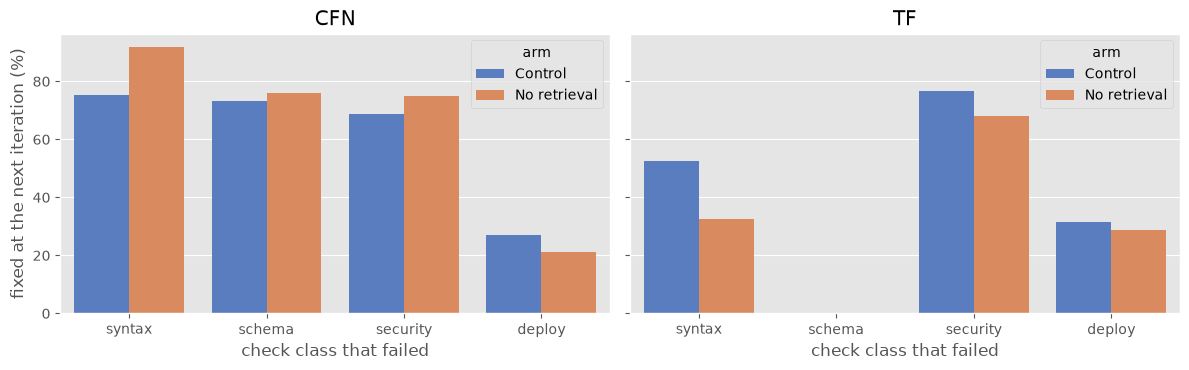

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, lang in zip(axes, EXPS):
    d = judged[(judged.lang == lang) & judged.arm.isin(["Control", "No retrieval"])].groupby(["cls", "arm"], observed=True).fixed.mean().mul(100).reset_index()
    sns.barplot(data=d, x="cls", y="fixed", hue="arm", hue_order=["Control", "No retrieval"], palette=PALETTE, ax=ax)
    ax.set_title(lang); ax.set_xlabel("check class that failed"); ax.set_ylabel("fixed at the next iteration (%)")
plt.tight_layout(); plt.savefig(FIG / "repair_turn_fix_rate.png", dpi=160); plt.show()

## Trivy audit of the final templates

In [21]:
def load_trivy(e):
    t = pd.read_csv(RES / f"Trivy_{e}.csv", engine="python")
    t = t.drop_duplicates("run_id")
    t = t.rename(columns={"severity_critical_failed": "critical", "severity_high_failed": "high", "severity_medium_failed": "medium", "severity_low_failed": "low"})
    t["findings"] = t[["critical", "high", "medium", "low"]].sum(axis=1)
    return t[["run_id", "trivy_passed", "critical", "high", "medium", "low", "findings", "total_checks"]]

tv = []
for e in [x for arms in EXPS.values() for x in arms.values()]:
    t = load_trivy(e)
    m = runs[(runs.exp == e) & runs.run_id.notna()][["run_id", "row_number", "passed", "valid", "lang", "arm", "difficulty"]].merge(t, on="run_id", how="left")
    tv.append(m)
TRIVY = pd.concat(tv, ignore_index=True)
TRIVY["arm"] = pd.Categorical(TRIVY.arm, ARMS, ordered=True)
scanned = TRIVY[TRIVY.findings.notna() & TRIVY.valid]
TRIVY_SUM = scanned.groupby(["lang", "arm"], observed=True).apply(lambda g: pd.Series(dict(
    templates=len(g), zero_findings_pct=100 * (g.findings == 0).mean(), with_critical_or_high_pct=100 * ((g.critical + g.high) > 0).mean(),
    mean_critical=g.critical.mean(), mean_high=g.high.mean(), mean_medium=g.medium.mean(), mean_low=g.low.mean(), mean_total=g.findings.mean(),
    median_total=g.findings.median()))).round(3)
TRIVY_SUM

templates  zero_findings_pct  with_critical_or_high_pct  mean_critical  mean_high  mean_medium  mean_low  mean_total  median_total
lang arm                                                                                                                                               
CFN  Control             250.0               40.8                        0.8          0.000      0.008        0.592     1.112       1.712           1.0
     No retrieval        250.0               37.2                        1.6          0.000      0.048        0.564     1.396       2.008           1.0
     All severities      250.0               97.2                        1.2          0.000      0.028        0.000     0.016       0.044           0.0
TF   Control             250.0               31.2                        0.4          0.016      0.004        0.808     1.064       1.892           1.0
     No retrieval        250.0               30.4                        0.8          0.000      0.020        0.908     1.236       2.164           1.0
     All severities      250.0               99.2                        0.8          0.004      0.016        0.000     0.004       0.024           0.0

In [22]:
sv = []
for e in [x for arms in EXPS.values() for x in arms.values()]:
    t = pd.read_csv(RES / f"Trivy_{e}.csv", engine="python").drop_duplicates("run_id")
    t = t[t.run_id.isin(runs.loc[runs.exp == e, "run_id"].dropna()) & t.total_checks.notna()]
    rec = dict(lang=LANG_OF[e], arm=ARM_OF[e], templates=len(t), policy_pass_pct=100 * (t.total_passed / t.total_checks).mean(),
               clean_pct=100 * t.trivy_passed.astype(bool).mean())
    for sev in ("critical", "high", "medium", "low"):
        rec[f"{sev}_pass_pct"] = 100 * t[f"severity_{sev}_passed"].sum() / t[f"severity_{sev}_eval"].sum()
    sv.append(rec)
SEV = pd.DataFrame(sv)
SEV["arm"] = pd.Categorical(SEV.arm, ARMS, ordered=True)
SEV = SEV.sort_values(["lang", "arm"]).round(2)
SEV

,lang,arm,templates,policy_pass_pct,clean_pct,critical_pass_pct,high_pass_pct,medium_pass_pct,low_pass_pct
0,CFN,Control,250,95.40,40.8,100.00,99.91,95.79,81.89
1,CFN,No retrieval,250,94.80,37.2,100.00,99.47,95.99,78.34
2,CFN,All severities,250,99.90,97.2,100.00,99.70,100.00,99.73
3,TF,Control,250,94.08,31.2,99.35,99.95,92.46,76.75
4,TF,No retrieval,250,93.26,30.4,100.00,99.75,91.53,73.66
5,TF,All severities,250,99.91,99.2,99.84,99.80,100.00,99.91


In [23]:
tp = []
for lang in EXPS:
    c = scanned[(scanned.lang == lang) & (scanned.arm == "Control")].set_index("row_number")
    for arm in ARMS[1:]:
        a = scanned[(scanned.lang == lang) & (scanned.arm == arm)].set_index("row_number")
        idx = c.index.intersection(a.index)
        for sev in ("critical", "high", "medium", "low", "findings"):
            d = (a.loc[idx, sev] - c.loc[idx, sev]).astype(float).dropna()
            mean, lo, hi = paired_bootstrap(d.values)
            nz = d[d != 0]
            tp.append(dict(lang=lang, arm=arm, severity=sev, rows=len(d), mean_diff=mean, ci_lo=lo, ci_hi=hi,
                           wilcoxon_p=stats.wilcoxon(nz).pvalue if len(nz) else 1.0))
TP = pd.DataFrame(tp)
TP["p_holm"] = np.nan
for lang in EXPS:
    m = TP.lang == lang
    TP.loc[m, "p_holm"] = holm(TP.loc[m, "wilcoxon_p"].values)
TP.round(4)

,lang,arm,severity,rows,mean_diff,ci_lo,ci_hi,wilcoxon_p,p_holm
0,CFN,No retrieval,critical,250,0.000,0.0000,0.0000,1.0000,1.0000
1,CFN,No retrieval,high,250,0.040,-0.0040,0.1040,0.3750,1.0000
2,CFN,No retrieval,medium,250,-0.028,-0.1400,0.0720,0.8239,1.0000
3,CFN,No retrieval,low,250,0.284,0.0880,0.5200,0.0067,0.0471
4,CFN,No retrieval,findings,250,0.296,0.0439,0.5760,0.0619,0.3713
5,CFN,All severities,critical,250,0.000,0.0000,0.0000,1.0000,1.0000
6,CFN,All severities,high,250,0.020,-0.0080,0.0680,0.7500,1.0000
7,CFN,All severities,medium,250,-0.592,-0.7760,-0.4360,0.0000,0.0000
8,CFN,All severities,low,250,-1.096,-1.3240,-0.8800,0.0000,0.0000
9,CFN,All severities,findings,250,-1.668,-2.0080,-1.3520,0.0000,0.0000


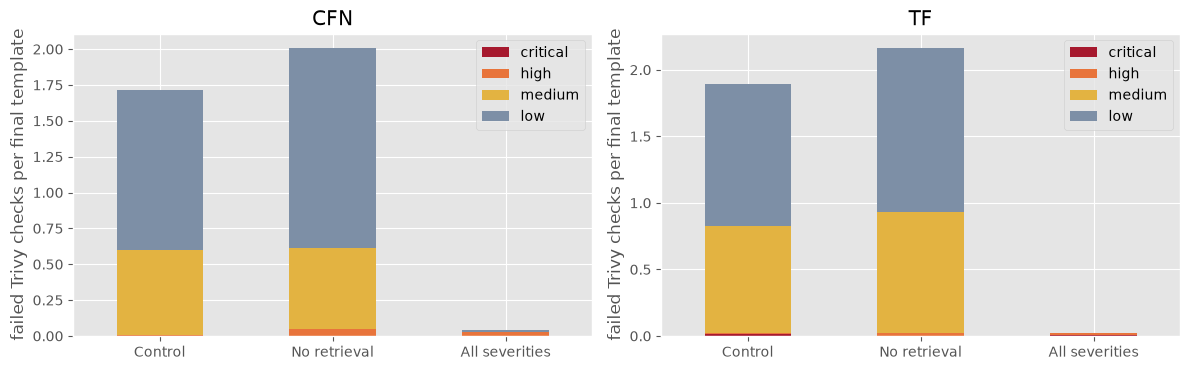

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, lang in zip(axes, EXPS):
    d = scanned[scanned.lang == lang].groupby("arm", observed=True)[["critical", "high", "medium", "low"]].mean()
    d.plot(kind="bar", stacked=True, ax=ax, color=["#a6192e", "#e8743b", "#e3b341", "#7d8fa6"], rot=0)
    ax.set_title(lang); ax.set_ylabel("failed Trivy checks per final template"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "trivy_findings.png", dpi=160); plt.show()

## Resource coverage of the final templates

In [25]:
COV_CFN = {"coverage_pct": "cov", "accuracy_pct": "acc", "correct_resources": "correct", "missing_resources": "missing", "extra_resources": "extra"}
COV_TF = {"resource_cov_pct": "cov", "resource_acc_pct": "acc", "resource_cor": "correct", "resource_missing": "missing", "resource_extra": "extra"}
cv = []
for e in [x for arms in EXPS.values() for x in arms.values()]:
    lang = LANG_OF[e]
    c = pd.read_csv(RES / f"Coverage_{e}.csv", engine="python")
    c = c.rename(columns=COV_CFN if lang == "CFN" else COV_TF)
    r = runs[(runs.exp == e) & runs.run_id.notna()][["row_number", "row_index", "run_id", "passed", "valid", "lang", "arm", "difficulty"]]
    if "row_number" in c:
        c = c.drop(columns=[x for x in ("difficulty", "difficulty_level") if x in c])
        m = r.merge(c[["row_number", "cov", "acc", "correct", "missing", "extra"]], on="row_number", how="left")
    else:
        m = r.merge(c[["row_index", "cov", "acc", "correct", "missing", "extra"]], on="row_index", how="left")
    cv.append(m)
COV = pd.concat(cv, ignore_index=True)
COV["arm"] = pd.Categorical(COV.arm, ARMS, ordered=True)
covv = COV[COV["cov"].notna() & COV.valid]
COV_SUM = covv.groupby(["lang", "arm"], observed=True).agg(templates=("cov", "size"), mean_cov=("cov", "mean"), mean_acc=("acc", "mean"),
                                                         full_cov_pct=("cov", lambda s: 100 * (s >= 100).mean()), mean_missing=("missing", "mean"), mean_extra=("extra", "mean")).round(2)
COV_SUM

templates  mean_cov  mean_acc  full_cov_pct  mean_missing  mean_extra
lang arm                                                                                  
CFN  Control               250     86.02     81.34          57.2          1.42        2.42
     No retrieval          250     86.51     79.48          58.4          1.35        2.92
     All severities        250     87.42     72.28          61.2          1.30        4.02
TF   Control               250     87.51     76.43          60.4          2.04        3.78
     No retrieval          250     84.99     81.41          53.6          2.14        2.76
     All severities        250     87.01     65.15          59.6          1.93        6.67

In [26]:
cp = []
for lang in EXPS:
    c = covv[(covv.lang == lang) & (covv.arm == "Control")].set_index("row_number")
    for arm in ARMS[1:]:
        a = covv[(covv.lang == lang) & (covv.arm == arm)].set_index("row_number")
        idx = c.index.intersection(a.index)
        for met in ("cov", "acc"):
            d = (a.loc[idx, met] - c.loc[idx, met]).astype(float).dropna()
            mean, lo, hi = paired_bootstrap(d.values)
            nz = d[d != 0]
            cp.append(dict(lang=lang, arm=arm, metric=met, rows=len(d), mean_diff=mean, ci_lo=lo, ci_hi=hi, wilcoxon_p=stats.wilcoxon(nz).pvalue if len(nz) else 1.0))
CP = pd.DataFrame(cp)
CP["p_holm"] = np.nan
for lang in EXPS:
    m = CP.lang == lang
    CP.loc[m, "p_holm"] = holm(CP.loc[m, "wilcoxon_p"].values)
CP.round(4)

,lang,arm,metric,rows,mean_diff,ci_lo,ci_hi,wilcoxon_p,p_holm
0,CFN,No retrieval,cov,250,0.4920,-1.1160,2.1703,0.3548,0.4531
1,CFN,No retrieval,acc,250,-1.8646,-4.6966,0.9697,0.2266,0.4531
2,CFN,All severities,cov,250,1.4005,0.1141,2.8364,0.0565,0.1694
3,CFN,All severities,acc,250,-9.0679,-12.0580,-6.0696,0.0000,0.0000
4,TF,No retrieval,cov,250,-2.5215,-4.9712,-0.1975,0.1824,0.3647
5,TF,No retrieval,acc,250,4.9762,2.3048,7.7733,0.0008,0.0023
6,TF,All severities,cov,250,-0.5001,-2.5141,1.3774,0.9731,0.9731
7,TF,All severities,acc,250,-11.2873,-14.8614,-7.7415,0.0000,0.0000


## Iterations to pass

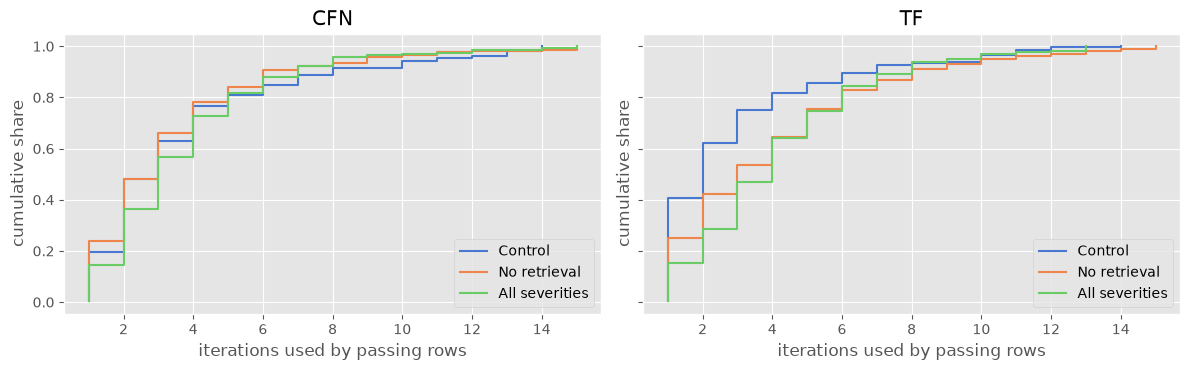

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, lang in zip(axes, EXPS):
    for arm in ARMS:
        g = runs[(runs.lang == lang) & (runs.arm == arm) & runs.valid & runs.passed].iterations_used.sort_values()
        ax.step(g, np.arange(1, len(g) + 1) / len(g), where="post", label=arm, color=PALETTE[arm])
    ax.set_title(lang); ax.set_xlabel("iterations used by passing rows"); ax.set_ylabel("cumulative share"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "iterations_ecdf.png", dpi=160); plt.show()

## Summary tables

In [28]:
SUMMARY = HEAD.merge(EFFORT.reset_index(), on=["lang", "arm"])
SUMMARY = SUMMARY.merge(TRIVY_SUM.reset_index()[["lang", "arm", "zero_findings_pct", "with_critical_or_high_pct", "mean_total"]], on=["lang", "arm"], how="left")
SUMMARY = SUMMARY.merge(COV_SUM.reset_index()[["lang", "arm", "mean_cov", "mean_acc"]], on=["lang", "arm"], how="left")
OUT = Path("result/final"); OUT.mkdir(parents=True, exist_ok=True)
SUMMARY.round(3).to_csv(OUT / "NoRetrieval_TrivyAll_summary.csv", index=False)
PAIRS.round(4).to_csv(OUT / "NoRetrieval_TrivyAll_paired_pass.csv", index=False)
METRICS.round(4).to_csv(OUT / "NoRetrieval_TrivyAll_paired_effort.csv", index=False)
TP.round(4).to_csv(OUT / "NoRetrieval_TrivyAll_paired_trivy.csv", index=False)
FAIL_TABLE.to_csv(OUT / "NoRetrieval_TrivyAll_failed_rows.csv", index=False)
VS_IACGEN.round(4).to_csv(OUT / "NoRetrieval_TrivyAll_vs_iacgen.csv", index=False)
FIXDIFF.round(3).to_csv(OUT / "NoRetrieval_repair_turn_fix_rate.csv", index=False)
SEV.to_csv(OUT / "NoRetrieval_TrivyAll_security.csv", index=False)
COV_SUM.reset_index().to_csv(OUT / "NoRetrieval_TrivyAll_resources.csv", index=False)
SUMMARY.round(3)

,lang,arm,rows,passed,failed,pass_rate,ci_lo,ci_hi,first_try_rate,mean_iterations,median_iterations,p90_iterations,hit_cap_15,mean_llm_calls,mean_tokens_k,median_tokens_k,max_tokens_m,total_tokens_m,median_minutes,total_hours,zero_findings_pct,with_critical_or_high_pct,mean_total,mean_cov,mean_acc
0,CFN,Control,250,247,3,0.988,0.965,0.996,0.192,3.844,3.0,8.0,3.0,10.148,151.111,39.514,2.239,37.778,9.182,88.248,40.8,0.8,1.712,86.02,81.34
1,CFN,No retrieval,250,234,16,0.936,0.899,0.960,0.224,4.116,3.0,10.0,19.0,8.232,361.875,56.540,17.683,90.469,8.322,101.673,37.2,1.6,2.008,86.51,79.48
2,CFN,All severities,250,236,14,0.944,0.908,0.966,0.136,4.368,3.0,8.0,16.0,11.032,193.316,50.946,2.392,48.329,4.910,49.719,97.2,1.2,0.044,87.42,72.28
3,TF,Control,250,246,4,0.984,0.960,0.994,0.400,3.100,2.0,7.0,4.0,7.976,141.284,27.360,2.358,35.321,8.836,69.728,31.2,0.4,1.892,87.51,76.43
4,TF,No retrieval,250,241,9,0.964,0.933,0.981,0.240,4.392,3.0,10.0,12.0,8.784,135.859,37.278,1.404,33.965,7.139,52.662,30.4,0.8,2.164,84.99,81.41
5,TF,All severities,250,239,11,0.956,0.923,0.975,0.148,4.624,4.0,9.0,11.0,11.456,233.743,93.016,3.014,58.436,12.283,93.737,99.2,0.8,0.024,87.01,65.15
